# Lab 9: Morphological Image Processing

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

## Load and binarize the image

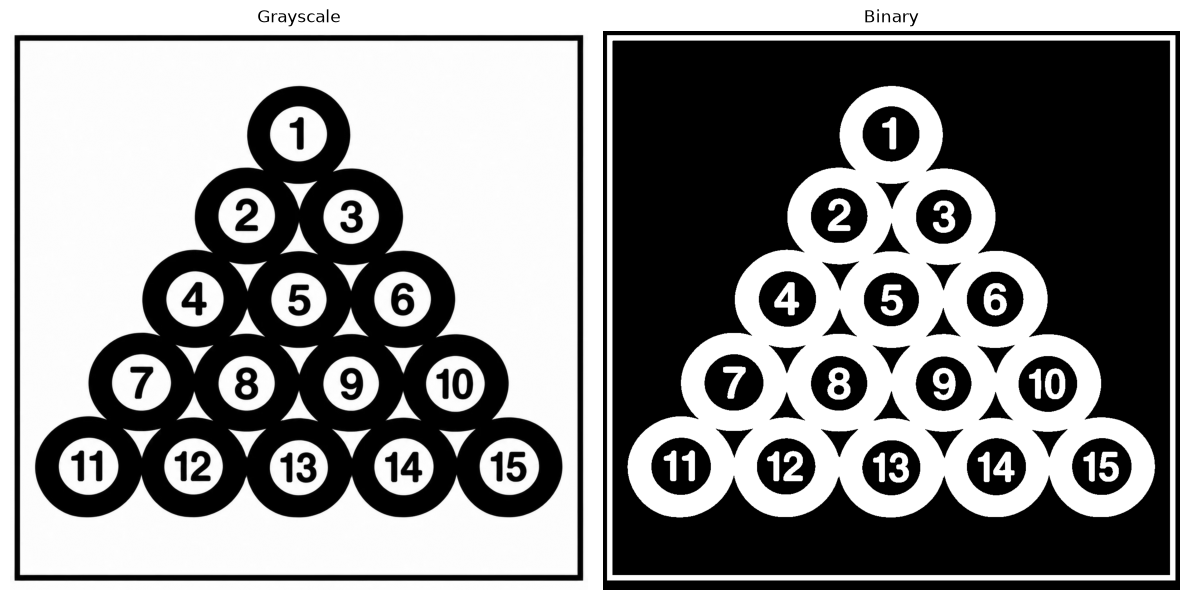

Image size: (1234, 1274)
Unique values: [  0 255]


In [2]:
gray = cv2.imread('balls.png', cv2.IMREAD_GRAYSCALE)
_, binary = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].imshow(gray, cmap='gray')
ax[0].set_title('Grayscale')
ax[1].imshow(binary, cmap='gray')
ax[1].set_title('Binary')
for a in ax:
    a.axis('off')
plt.tight_layout()
plt.show()

print('Image size:', binary.shape)
print('Unique values:', np.unique(binary))

## Task 1: Morphological operations on the Balls image

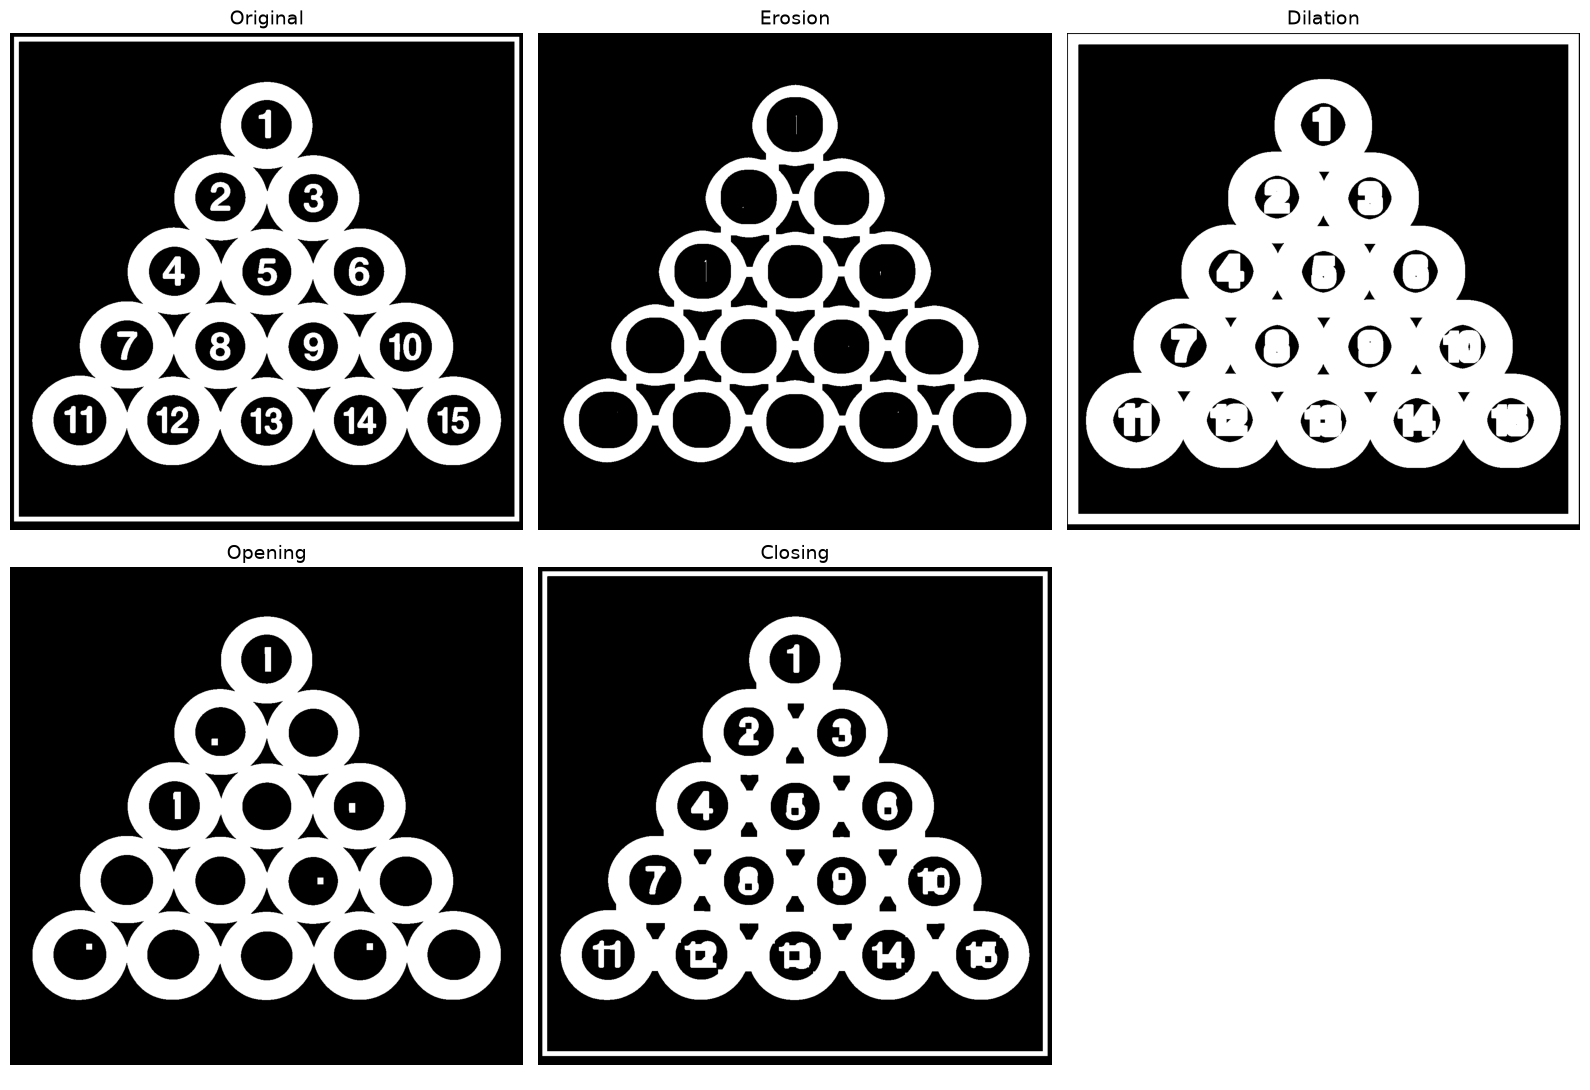

In [3]:
kernel = np.ones((15, 15), np.uint8)

erosion = cv2.erode(binary, kernel, iterations=1)
dilation = cv2.dilate(binary, kernel, iterations=1)
opening = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)
closing = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)

images = [binary, erosion, dilation, opening, closing]
titles = ['Original', 'Erosion', 'Dilation', 'Opening', 'Closing']

fig, ax = plt.subplots(2, 3, figsize=(16, 11))
ax = ax.ravel()
for a, img, t in zip(ax, images, titles):
    a.imshow(img, cmap='gray')
    a.set_title(t, fontsize=14)
    a.axis('off')
ax[5].axis('off')
plt.tight_layout()
plt.show()

In [4]:
for img, t in zip(images, titles):
    print(f'{t:<10} foreground pixels: {cv2.countNonZero(img)}')

Original   foreground pixels: 500315
Erosion    foreground pixels: 278046
Dilation   foreground pixels: 720943
Opening    foreground pixels: 412110
Closing    foreground pixels: 515929


## Task 2: Experimenting with structuring elements

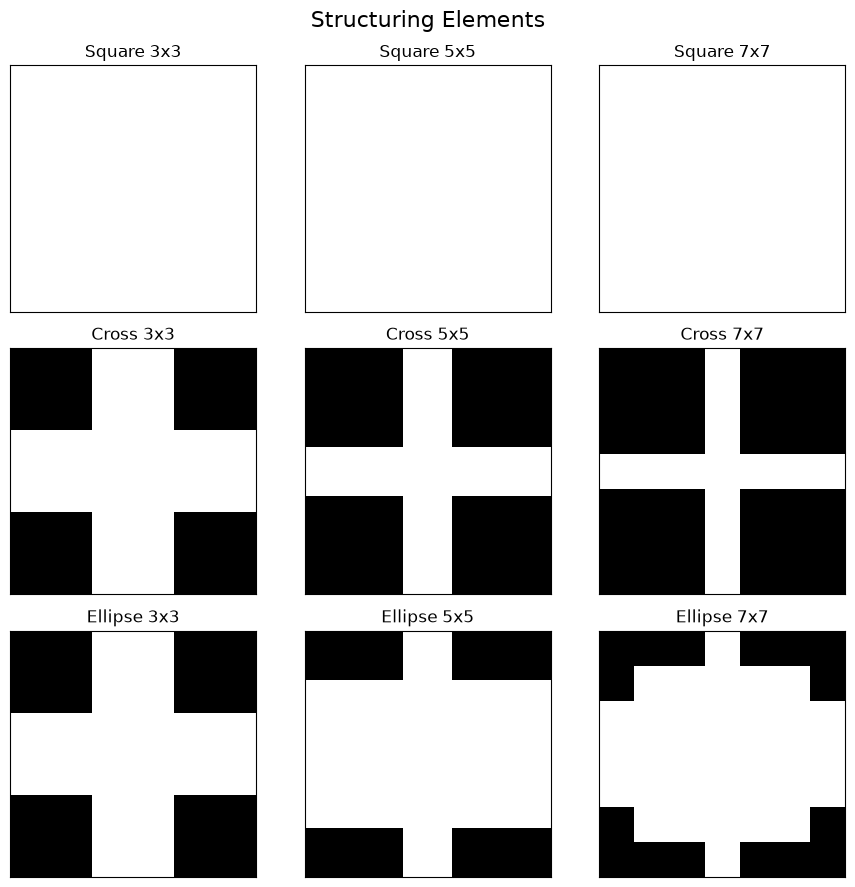

Square 5x5:
[[1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]] 

Cross 5x5:
[[0 0 1 0 0]
 [0 0 1 0 0]
 [1 1 1 1 1]
 [0 0 1 0 0]
 [0 0 1 0 0]] 

Ellipse 5x5:
[[0 0 1 0 0]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [0 0 1 0 0]] 



In [5]:
shapes = {'Square': cv2.MORPH_RECT, 'Cross': cv2.MORPH_CROSS, 'Ellipse': cv2.MORPH_ELLIPSE}
sizes = [3, 5, 7]

fig, ax = plt.subplots(3, 3, figsize=(9, 9))
for i, (name, shape) in enumerate(shapes.items()):
    for j, s in enumerate(sizes):
        k = cv2.getStructuringElement(shape, (s, s))
        ax[i, j].imshow(k, cmap='gray', vmin=0, vmax=1)
        ax[i, j].set_title(f'{name} {s}x{s}')
        ax[i, j].set_xticks([])
        ax[i, j].set_yticks([])
plt.suptitle('Structuring Elements', fontsize=16)
plt.tight_layout()
plt.show()

for name, shape in shapes.items():
    print(name, '5x5:')
    print(cv2.getStructuringElement(shape, (5, 5)), '\n')

In [6]:
def compare(operation, op_name, iterations=1):
    fig, ax = plt.subplots(3, 3, figsize=(15, 15))
    for i, (name, shape) in enumerate(shapes.items()):
        for j, s in enumerate(sizes):
            k = cv2.getStructuringElement(shape, (s, s))
            result = operation(binary, k, iterations=iterations)
            ax[i, j].imshow(result, cmap='gray')
            ax[i, j].set_title(f'{op_name} - {name} {s}x{s}', fontsize=12)
            ax[i, j].axis('off')
    plt.suptitle(f'{op_name} with different structuring elements (iterations={iterations})', fontsize=16)
    plt.tight_layout()
    plt.show()

### Erosion

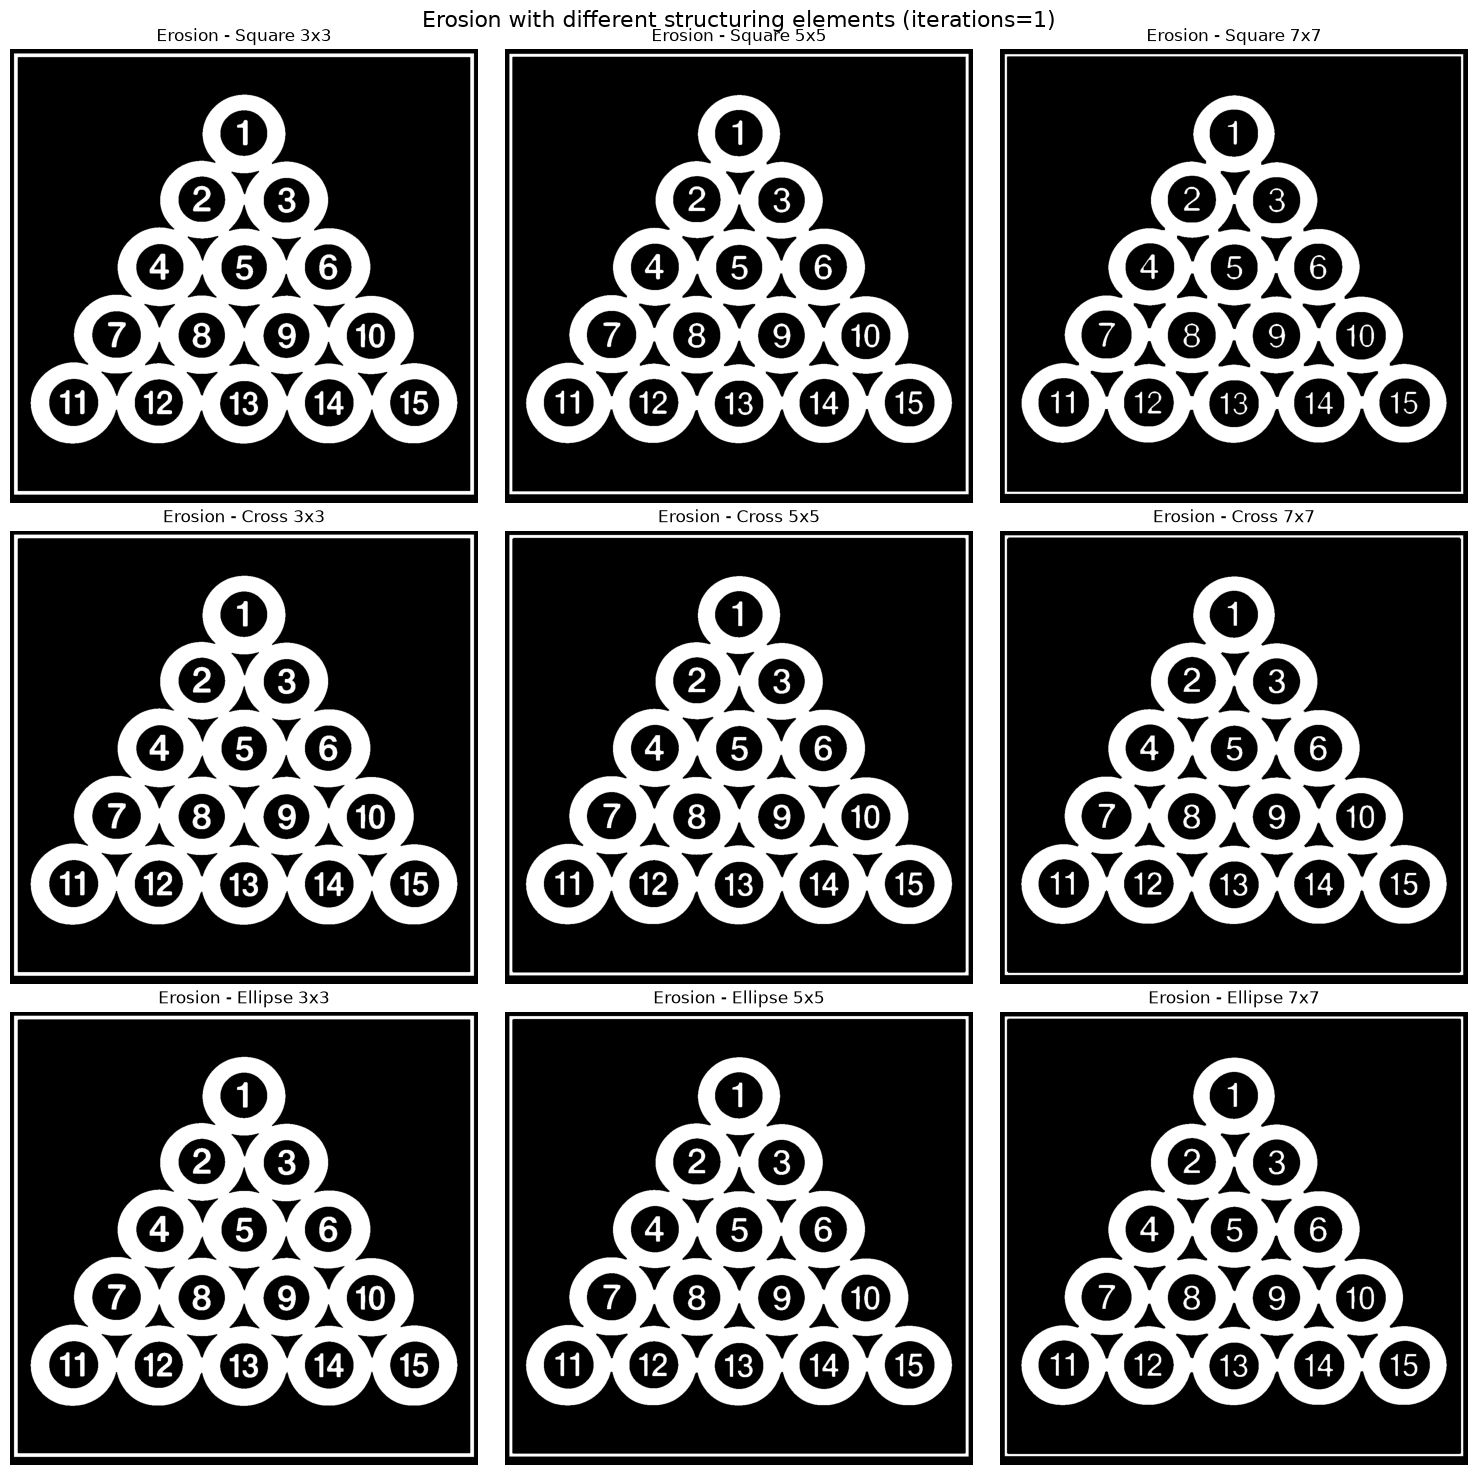

In [7]:
compare(cv2.erode, 'Erosion')

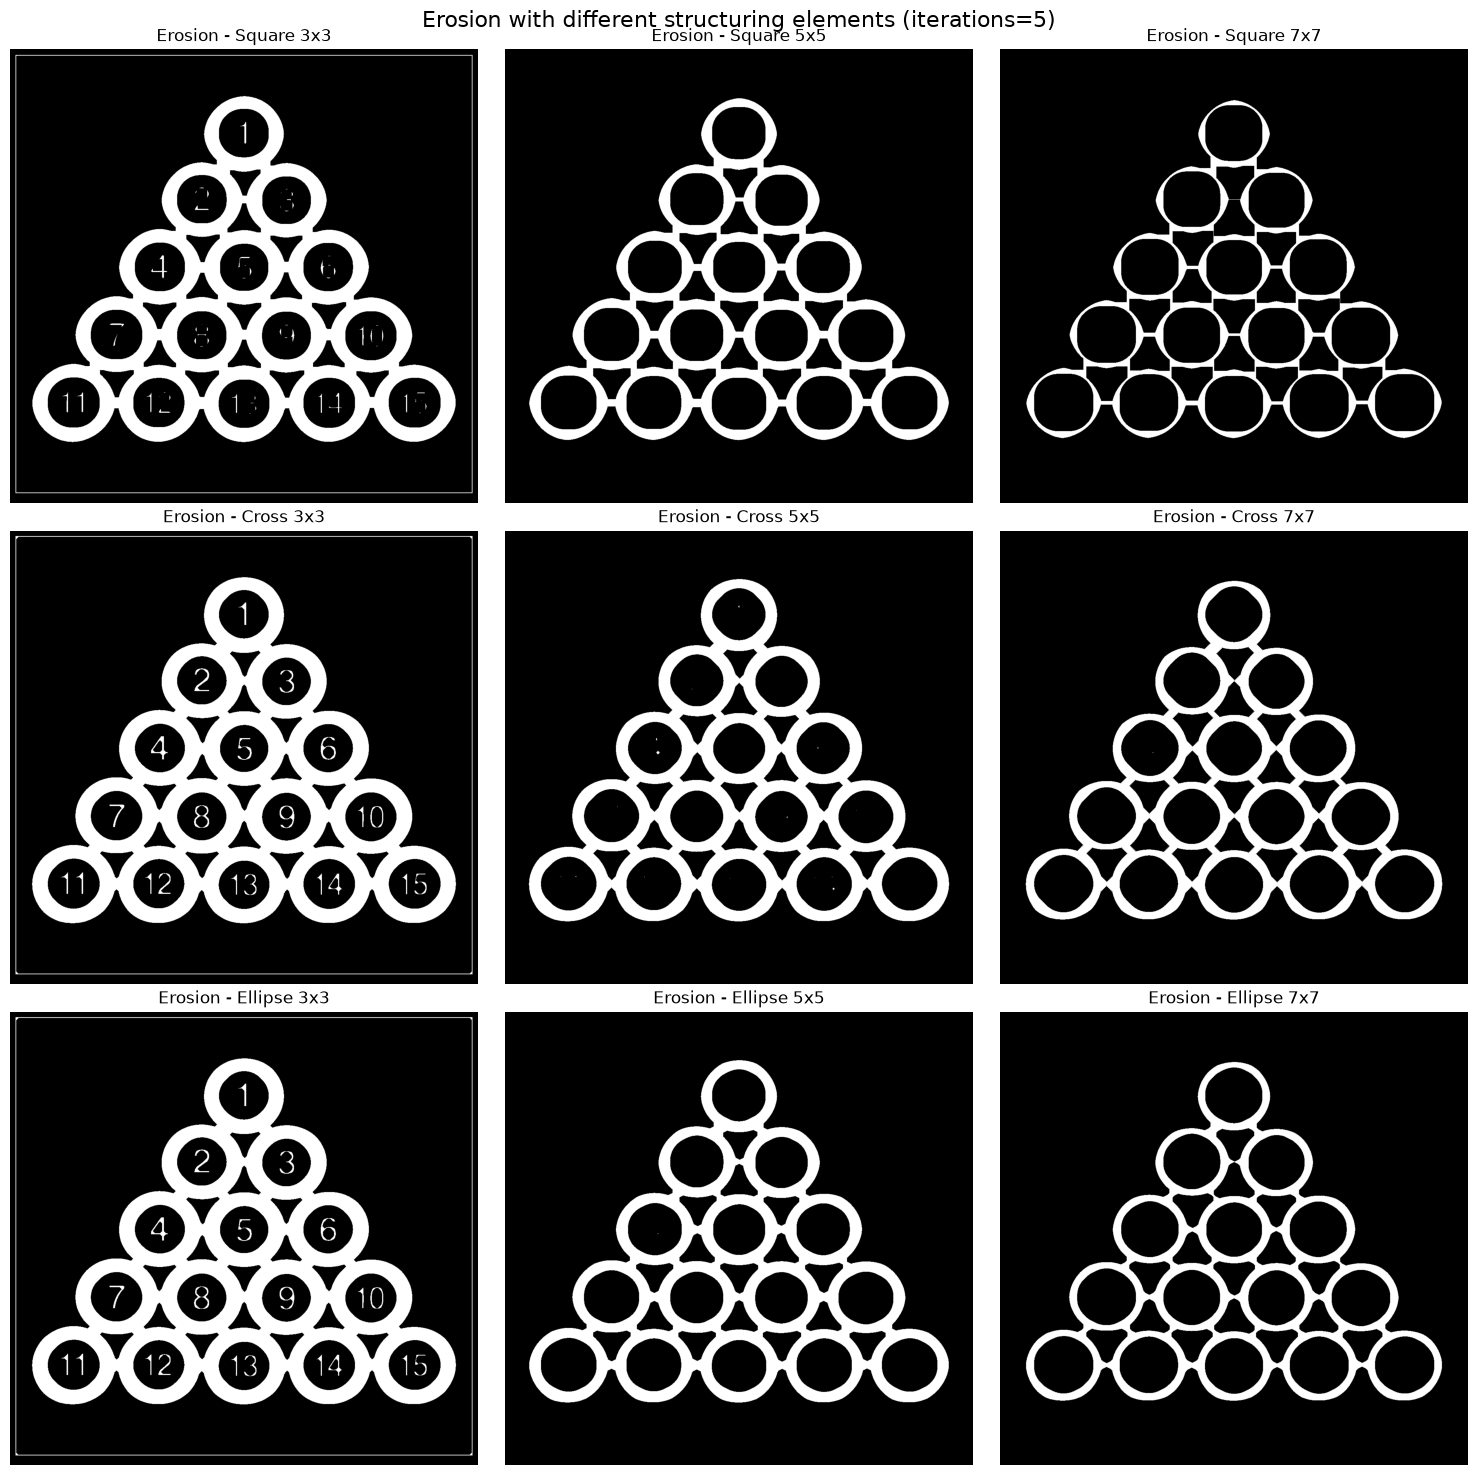

In [8]:
compare(cv2.erode, 'Erosion', iterations=5)

### Dilation

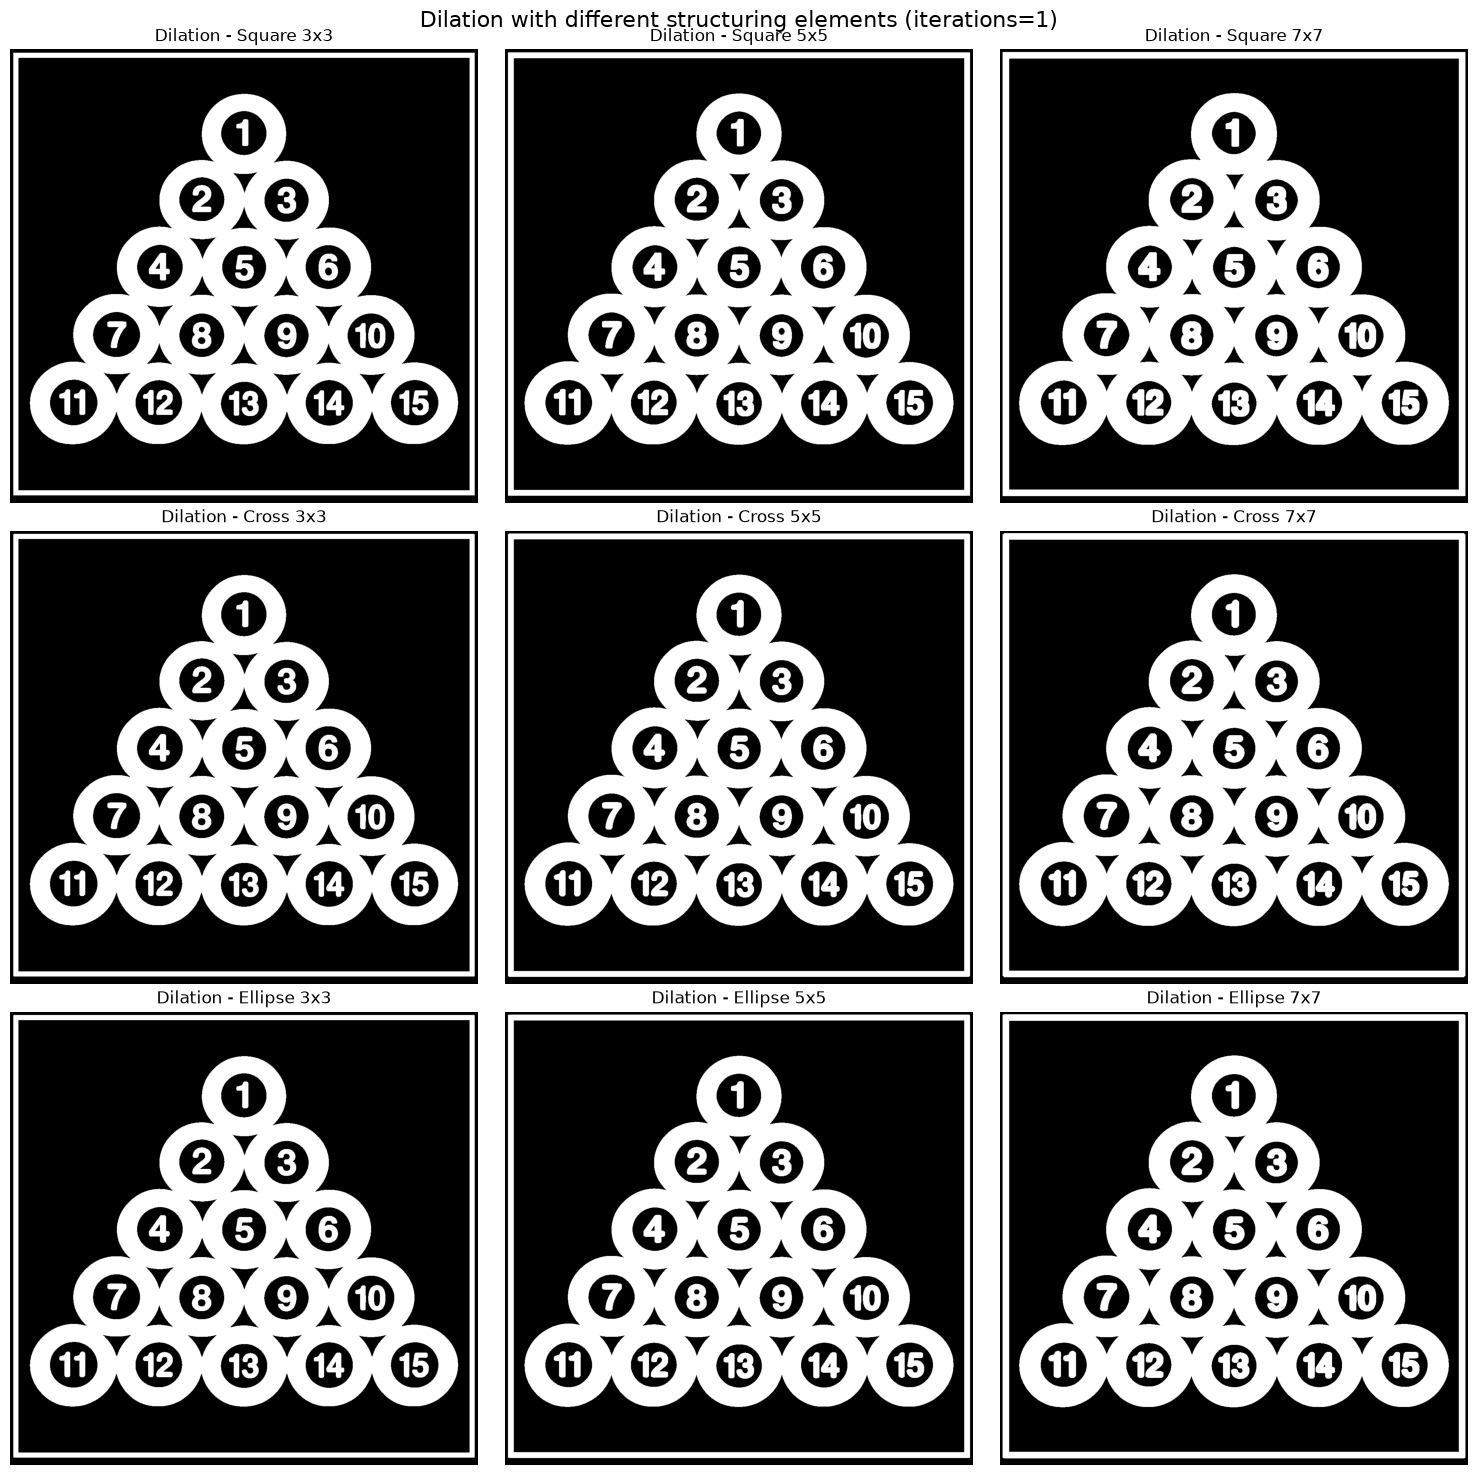

In [9]:
compare(cv2.dilate, 'Dilation')

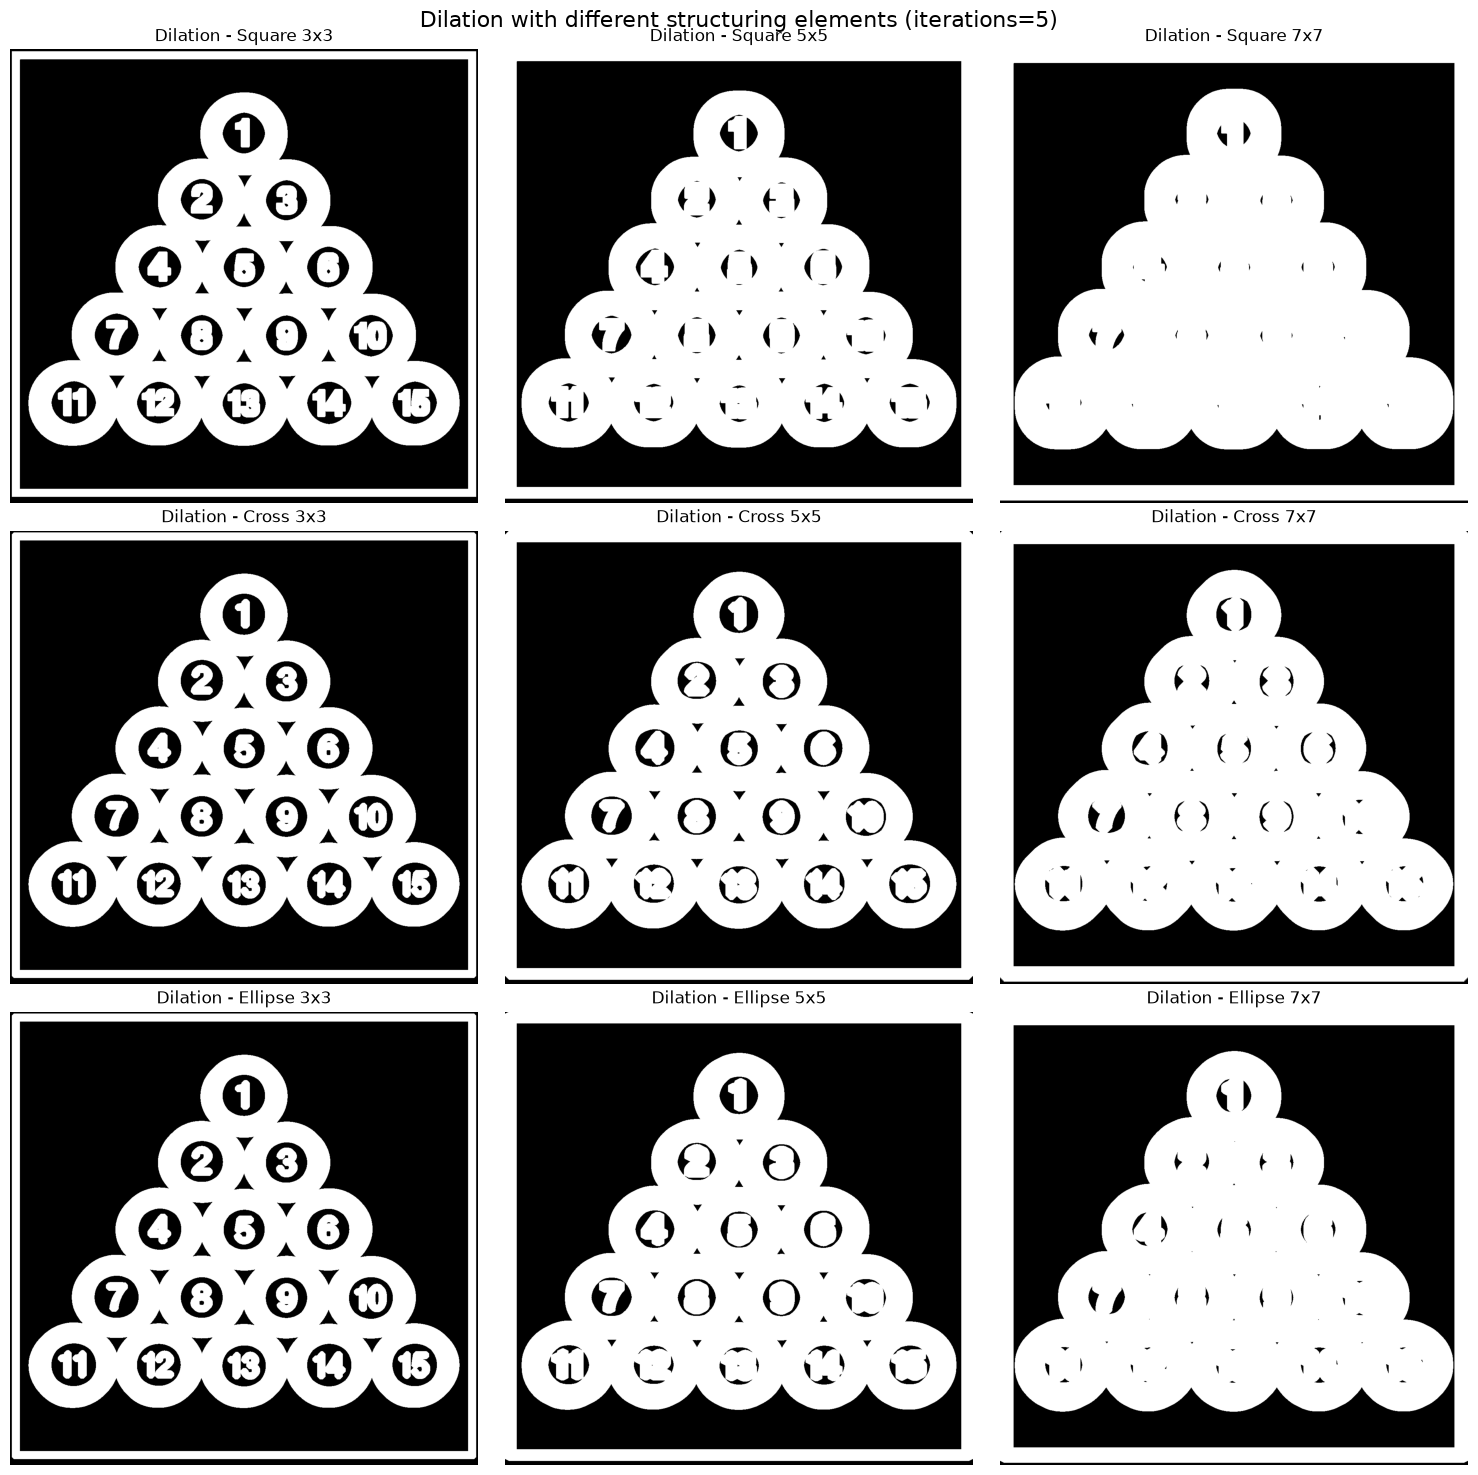

In [10]:
compare(cv2.dilate, 'Dilation', iterations=5)

### Close-up comparison

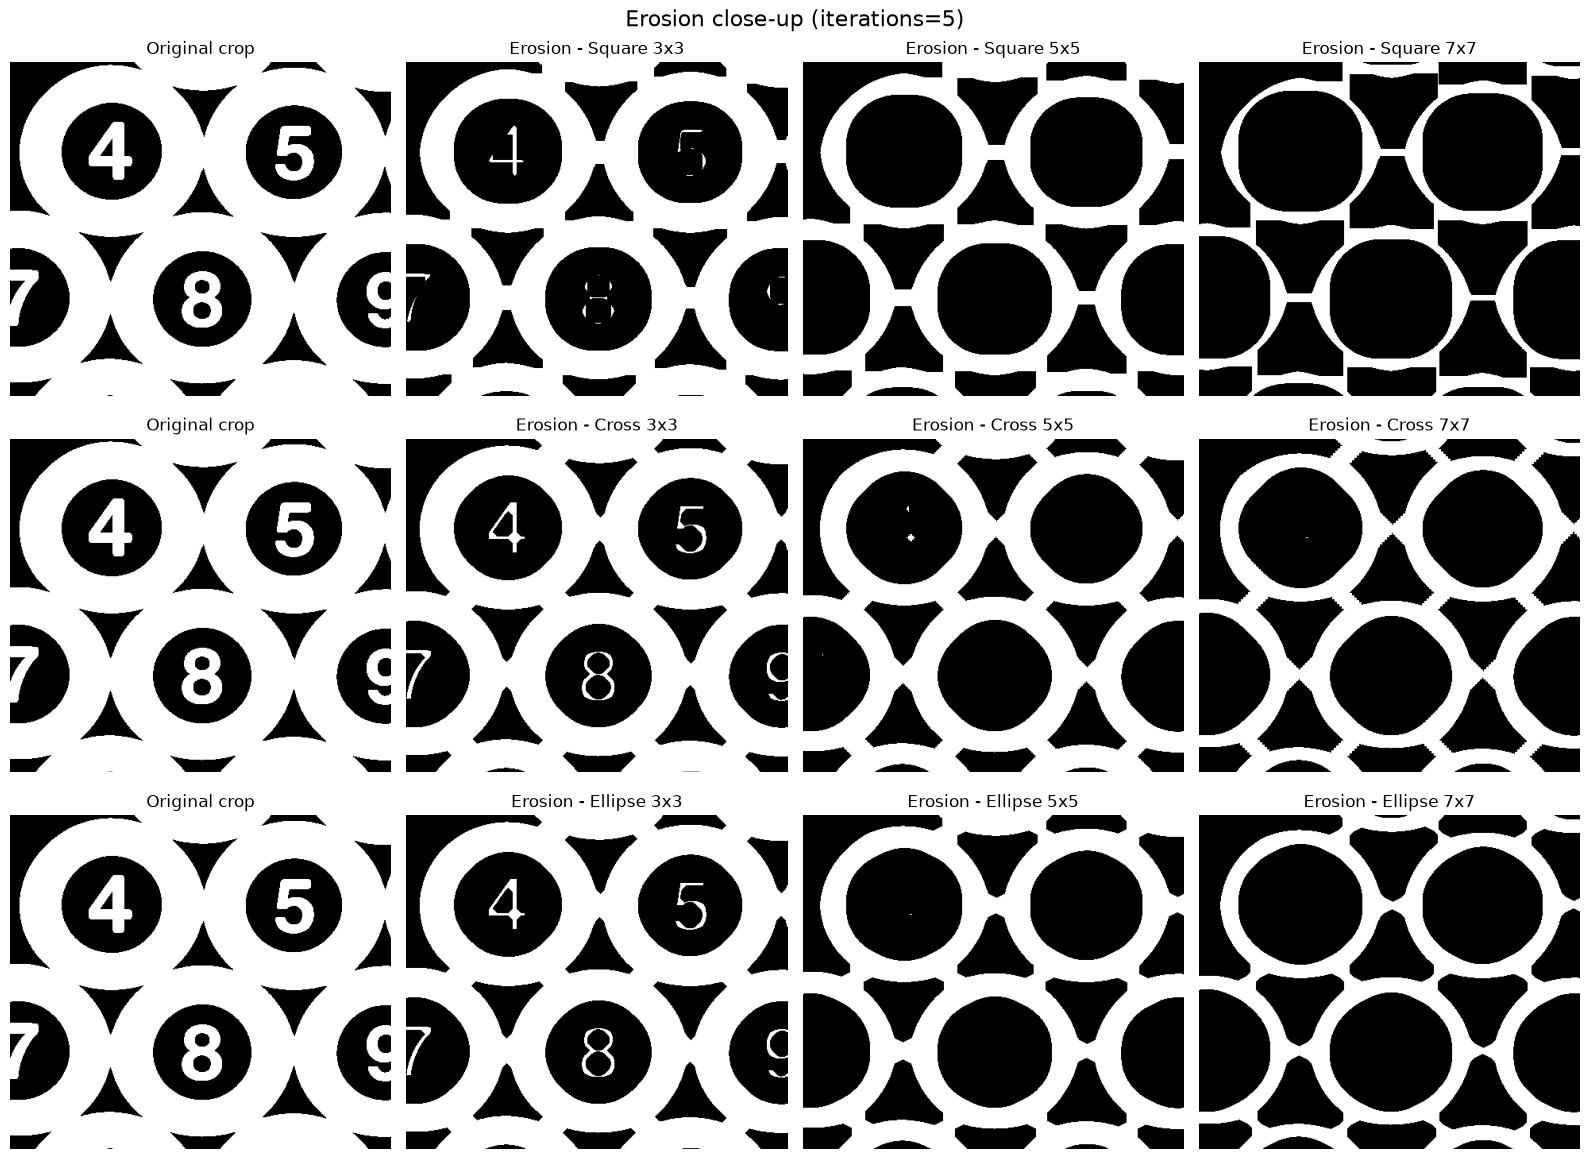

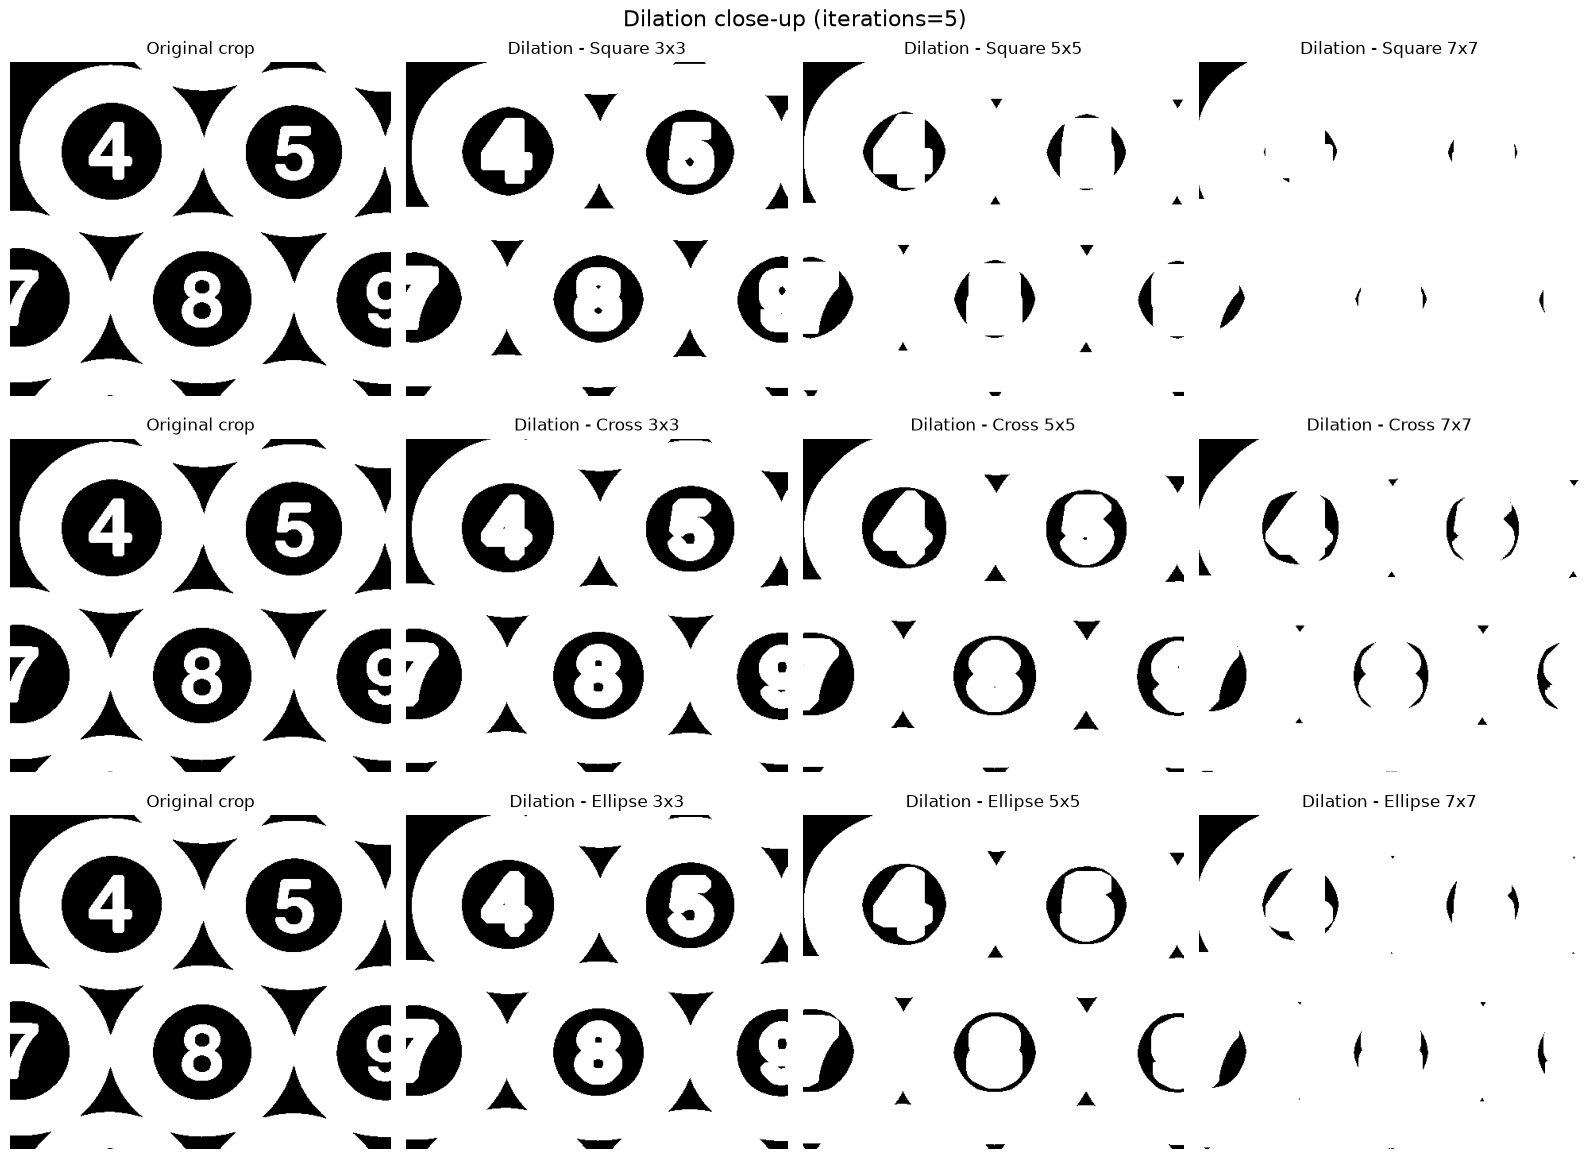

In [11]:
y1, y2, x1, x2 = 480, 900, 280, 760
crop = binary[y1:y2, x1:x2]

for op, op_name in [(cv2.erode, 'Erosion'), (cv2.dilate, 'Dilation')]:
    fig, ax = plt.subplots(3, 4, figsize=(16, 12))
    for i, (name, shape) in enumerate(shapes.items()):
        ax[i, 0].imshow(crop, cmap='gray')
        ax[i, 0].set_title('Original crop')
        ax[i, 0].axis('off')
        for j, s in enumerate(sizes):
            k = cv2.getStructuringElement(shape, (s, s))
            ax[i, j + 1].imshow(op(binary, k, iterations=5)[y1:y2, x1:x2], cmap='gray')
            ax[i, j + 1].set_title(f'{op_name} - {name} {s}x{s}')
            ax[i, j + 1].axis('off')
    plt.suptitle(f'{op_name} close-up (iterations=5)', fontsize=16)
    plt.tight_layout()
    plt.show()

### Quantitative comparison

In [12]:
base = cv2.countNonZero(binary)
print(f'Original foreground pixels: {base}\n')
print(f"{'Shape':<10}{'Size':<8}{'Erosion':>12}{'Change %':>11}{'Dilation':>12}{'Change %':>11}")
print('-' * 64)
rows = []
for name, shape in shapes.items():
    for s in sizes:
        k = cv2.getStructuringElement(shape, (s, s))
        e = cv2.countNonZero(cv2.erode(binary, k))
        d = cv2.countNonZero(cv2.dilate(binary, k))
        rows.append((name, s, e, d))
        print(f'{name:<10}{str(s) + "x" + str(s):<8}{e:>12}{(e - base) / base * 100:>10.2f}%{d:>12}{(d - base) / base * 100:>10.2f}%')

Original foreground pixels: 500315

Shape     Size         Erosion   Change %    Dilation   Change %
----------------------------------------------------------------
Square    3x3           466337     -6.79%      534035      6.74%
Square    5x5           432238    -13.61%      567068     13.34%
Square    7x7           398032    -20.44%      599441     19.81%
Cross     3x3           473051     -5.45%      527499      5.43%
Cross     5x5           445874    -10.88%      554322     10.79%
Cross     7x7           418794    -16.29%      580756     16.08%
Ellipse   3x3           473051     -5.45%      527499      5.43%
Ellipse   5x5           440728    -11.91%      559161     11.76%
Ellipse   7x7           413282    -17.40%      585635     17.05%


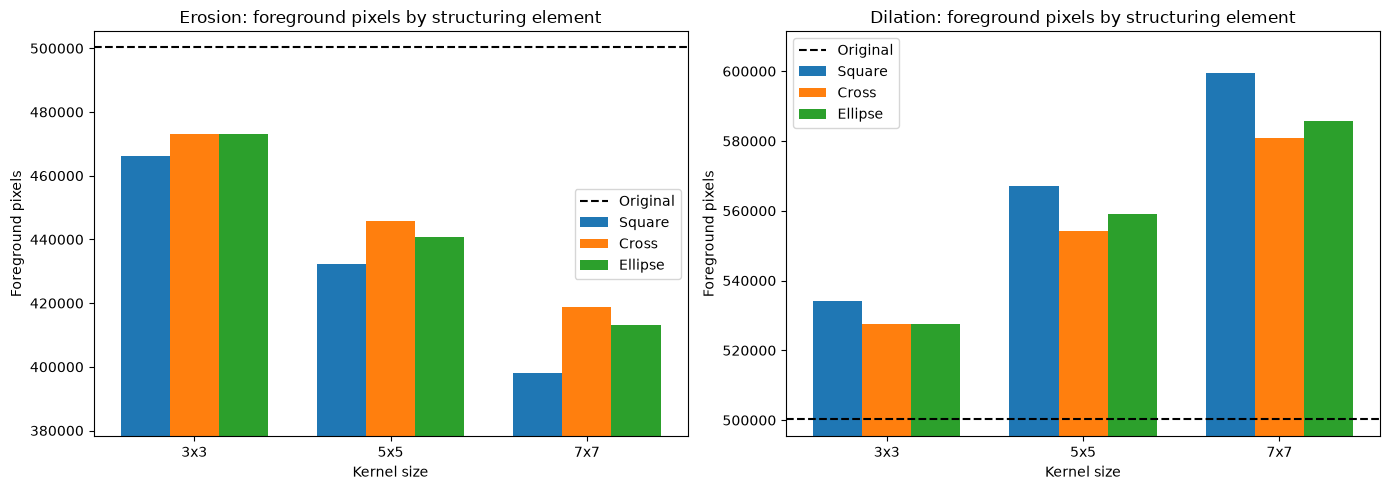

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
x = np.arange(len(sizes))
w = 0.25
for idx, name in enumerate(shapes):
    e = [r[2] for r in rows if r[0] == name]
    d = [r[3] for r in rows if r[0] == name]
    ax[0].bar(x + (idx - 1) * w, e, w, label=name)
    ax[1].bar(x + (idx - 1) * w, d, w, label=name)
for a, t in zip(ax, ['Erosion', 'Dilation']):
    a.axhline(base, color='k', linestyle='--', label='Original')
    a.set_xticks(x)
    a.set_xticklabels([f'{s}x{s}' for s in sizes])
    a.set_xlabel('Kernel size')
    a.set_ylabel('Foreground pixels')
    a.set_title(f'{t}: foreground pixels by structuring element')
    a.legend()
ax[0].set_ylim(min(r[2] for r in rows) * 0.95, base * 1.01)
ax[1].set_ylim(base * 0.99, max(r[3] for r in rows) * 1.02)
plt.tight_layout()
plt.show()